In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import math
import os
import os.path
import time

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotnine as pn
import shapely
import scipy
import xarray as xr

from shoreshop3_analysis import util, data, wct, wavelet, transect_loaders, plot

In [94]:
ds = xr.open_zarr(data.global_coherence_path, consolidated=False)
ds

<xarray.Dataset> Size: 279kB
Dimensions:    (model: 71, transect: 2, scale: 119)
Coordinates:
  * model      (model) <U28 8kB 'Cohn.CSHORE' 'Devoe.BruunSLR' ... 'Traboulsi'
  * transect   (transect) <U6 48B '1.0' '1006.0'
  * scale      (scale) int64 952B 0 1 2 3 4 5 6 ... 112 113 114 115 116 117 118
Data variables:
    period     (model, transect, scale) float64 135kB dask.array<chunksize=(1, 1, 119), meta=np.ndarray>
    coherence  (model, transect, scale) float64 135kB dask.array<chunksize=(1, 1, 119), meta=np.ndarray>
Attributes:
    title:    
    source:

In [97]:
len(np.array((~np.isnan(ds.period[:, :, 0].values)).nonzero()).T)

71

In [99]:
ds.period[:, 1, :].values

array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(71, 119))

In [80]:
ds.period[1, 0, :].values == ds.period[1, 1, :].values

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False])

In [100]:
coh = ds.coherence.values
coh

array([[[0.31816099, 0.29402453, 0.27396584, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.34120913, 0.31896099, 0.29797644, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.34204307, 0.32000109, 0.30079122, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       ...,

       [[0.34085861, 0.31770922, 0.29680006, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.40903326, 0.39589293, 0.38615138, ...,        nan,
                nan,        nan],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[0.329141

In [101]:
coh[coh < 0] = np.nan
coh[coh > 1] = np.nan

In [102]:
mean = np.nanmean(coh, axis=1)
mean

/tmp/ipykernel_2529584/3444397126.py:1: RuntimeWarning: Mean of empty slice


array([[0.31816099, 0.29402453, 0.27396584, ...,        nan,        nan,
               nan],
       [0.34120913, 0.31896099, 0.29797644, ...,        nan,        nan,
               nan],
       [0.34204307, 0.32000109, 0.30079122, ...,        nan,        nan,
               nan],
       ...,
       [0.34085861, 0.31770922, 0.29680006, ...,        nan,        nan,
               nan],
       [0.40903326, 0.39589293, 0.38615138, ...,        nan,        nan,
               nan],
       [0.32914143, 0.31786681, 0.30222445, ...,        nan,        nan,
               nan]], shape=(71, 119))

In [103]:
period_mask = ~np.isnan(mean).all(axis=0)
mean = mean[:, period_mask]
mean

array([[0.31816099, 0.29402453, 0.27396584, ..., 0.32962728, 0.30585829,
        0.28702697],
       [0.34120913, 0.31896099, 0.29797644, ..., 0.36594697, 0.4599652 ,
        0.53789715],
       [0.34204307, 0.32000109, 0.30079122, ..., 0.43935761, 0.43766003,
        0.45224129],
       ...,
       [0.34085861, 0.31770922, 0.29680006, ..., 0.84463337, 0.87003492,
        0.90435895],
       [0.40903326, 0.39589293, 0.38615138, ..., 0.99647864, 0.99701029,
        0.99770485],
       [0.32914143, 0.31786681, 0.30222445, ..., 0.58691952, 0.55502555,
        0.54429678]], shape=(71, 101))

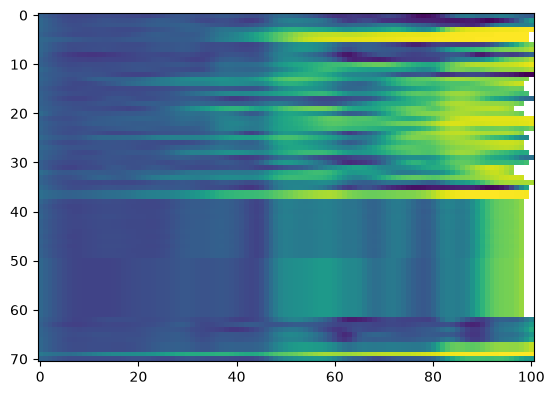

In [104]:
plt.imshow(mean, cmap='viridis')

In [105]:
np.min(mean[~np.isnan(mean)]), np.max(mean[~np.isnan(mean)])

(np.float64(0.0105068302955948), np.float64(0.9990870999974131))

In [106]:
mean.shape

(71, 101)

In [107]:
mean_tosort = mean.copy()
mean_tosort[np.isnan(mean_tosort)] = 0
order = np.argsort(mean_tosort, axis=0)[::-1]
rank = np.argsort(order, axis=0)
rank

array([[54, 59, 58, ..., 65, 33, 24],
       [22, 23, 17, ..., 63, 28, 17],
       [ 9, 10, 13, ..., 59, 29, 20],
       ...,
       [24, 28, 32, ..., 16, 10,  5],
       [ 0,  0,  0, ...,  2,  2,  0],
       [34, 26, 11, ..., 53, 22, 16]], shape=(71, 101))

In [108]:
df = pd.DataFrame({
    'model': np.repeat(ds.model.values, mean.shape[1]),
    'period': np.tile(ds.period[1, 0, period_mask].values, mean.shape[0]),
    'coherence': mean.flatten(),
    'rank': rank.flatten(),
})

df

,model,period,coherence,rank
0,Cohn.CSHORE,16.000000,0.318161,54
1,Cohn.CSHORE,16.951410,0.294025,59
2,Cohn.CSHORE,17.959393,0.273966,58
3,Cohn.CSHORE,19.027314,0.257684,52
4,Cohn.CSHORE,20.158737,0.244932,53
...,...,...,...,...
7166,Traboulsi,4096.000000,0.665682,54
7167,Traboulsi,4339.560834,0.628729,51
7168,Traboulsi,4597.604550,0.586920,53
7169,Traboulsi,4870.992343,0.555026,22


In [109]:
df[pd.isna(df['coherence'])]

,model,period,coherence,rank
504,CSIRO.CWaCS,5160.636620,NaN,69
605,CSIRO.CWaCS.smooth,5160.636620,NaN,70
1413,IHC.Crossformer,5160.636620,NaN,66
1513,IHC.DLinear,4870.992343,NaN,69
1514,IHC.DLinear,5160.636620,NaN,67
...,...,...,...,...
6059,ShEPreMo.dec.MIR585.S01,5160.636620,NaN,27
6159,ShEPreMo.dec.MPI245.S01,4870.992343,NaN,38
6160,ShEPreMo.dec.MPI245.S01,5160.636620,NaN,30
6260,ShEPreMo.dec.MPI585.S01,4870.992343,NaN,37


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 8 x 8 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/mean-coherence.png


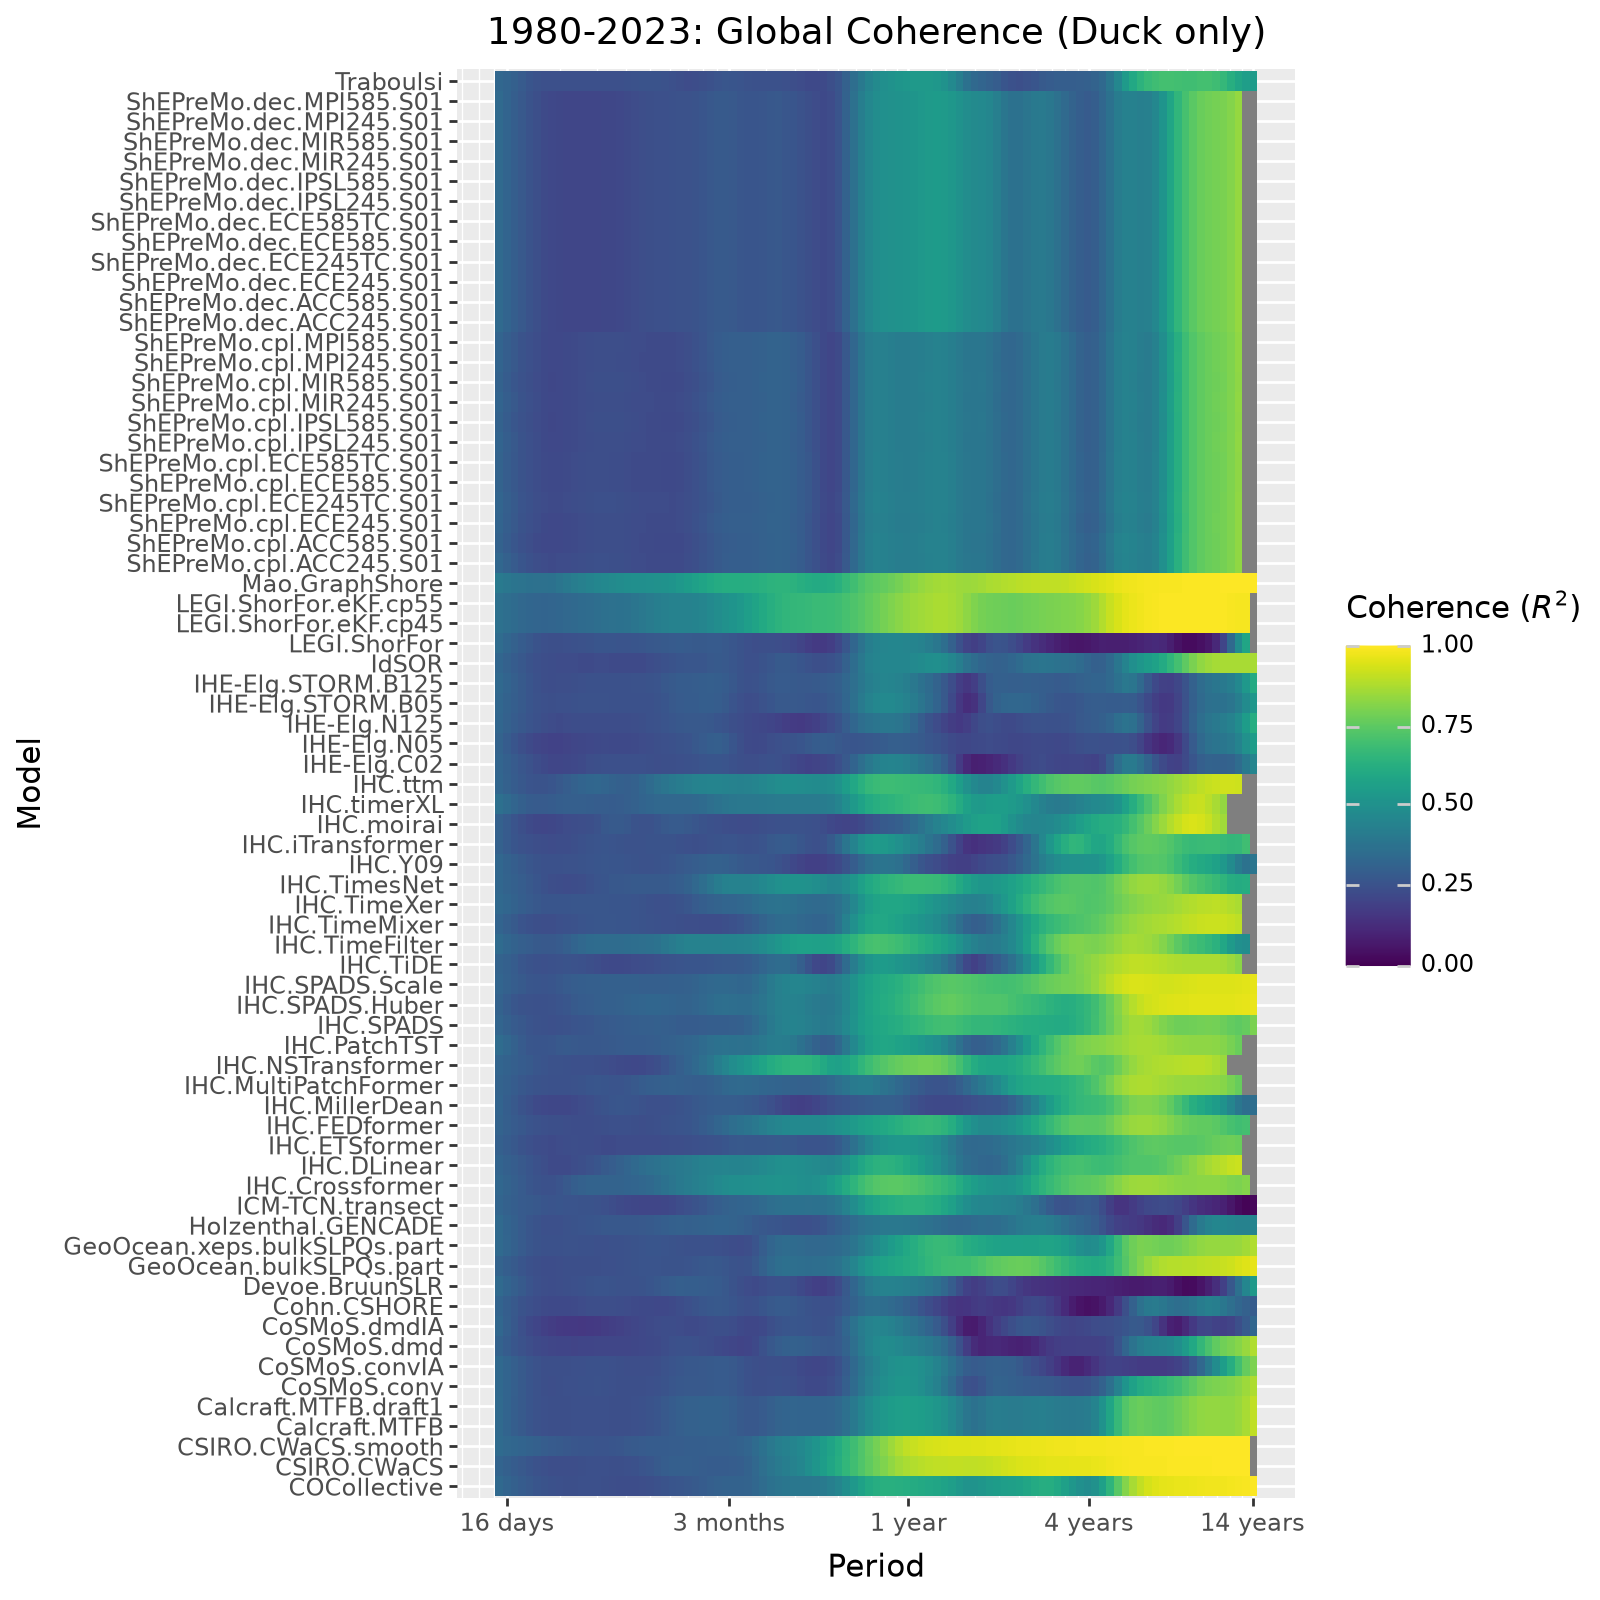

In [111]:
p = (
    pn.ggplot(df)
    + pn.geom_tile(pn.aes('period', 'model', fill='coherence'))
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
    )
    + pn.scale_fill_continuous(limits=(0, 1), cmap_name='viridis')
    + pn.labs(x='Period', y='Model', title='1980-2023: Global Coherence (Duck only)', fill='Coherence ($R^2$)')
    + pn.theme(figure_size=(8, 8))
)
p.save('../figures/mean-coherence.png', dpi=180)
p

In [112]:
df_nonan = df[~df['coherence'].isna()] #.groupby(df['model']).transform('all')]
#df_nonan['rank'] = np.minimum(df_nonan['rank'].values, len(df_nonan['model'].unique()))
# df_nonan = df_nonan[df_nonan['period'].isin(df_nonan['period'].unique()[::2])]
mean_rank = df_nonan['rank'].groupby(df['model']).mean().argsort().argsort()
k = 10
topk = mean_rank[mean_rank < k]
print(topk.index.unique())
df_nonan = df_nonan[df_nonan['model'].isin(topk.index)]
df_nonan['rank'] = df_nonan.groupby('period')['coherence'].rank(method='first', ascending=False).astype(int) - 1
df_nonan

Index(['CSIRO.CWaCS', 'CSIRO.CWaCS.smooth', 'IHC.Crossformer',
       'IHC.SPADS.Huber', 'IHC.SPADS.Scale', 'IHC.TimeFilter', 'IHC.ttm',
       'LEGI.ShorFor.eKF.cp45', 'LEGI.ShorFor.eKF.cp55', 'Mao.GraphShore'],
      dtype='str', name='model')


,model,period,coherence,rank
404,CSIRO.CWaCS,16.000000,0.320272,8
405,CSIRO.CWaCS,16.951410,0.302672,8
406,CSIRO.CWaCS,17.959393,0.287642,7
407,CSIRO.CWaCS,19.027314,0.274640,7
408,CSIRO.CWaCS,20.158737,0.263494,7
...,...,...,...,...
7065,Mao.GraphShore,4096.000000,0.996094,2
7066,Mao.GraphShore,4339.560834,0.996208,2
7067,Mao.GraphShore,4597.604550,0.996479,2
7068,Mao.GraphShore,4870.992343,0.997010,2


/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:623: PlotnineWarning: Saving 15 x 6 in image.
/hpc/home/sln33/shoreshop3-wavelets/venv/lib/python3.14/site-packages/plotnine/ggplot.py:624: PlotnineWarning: Filename: ../figures/topk-ranks.png


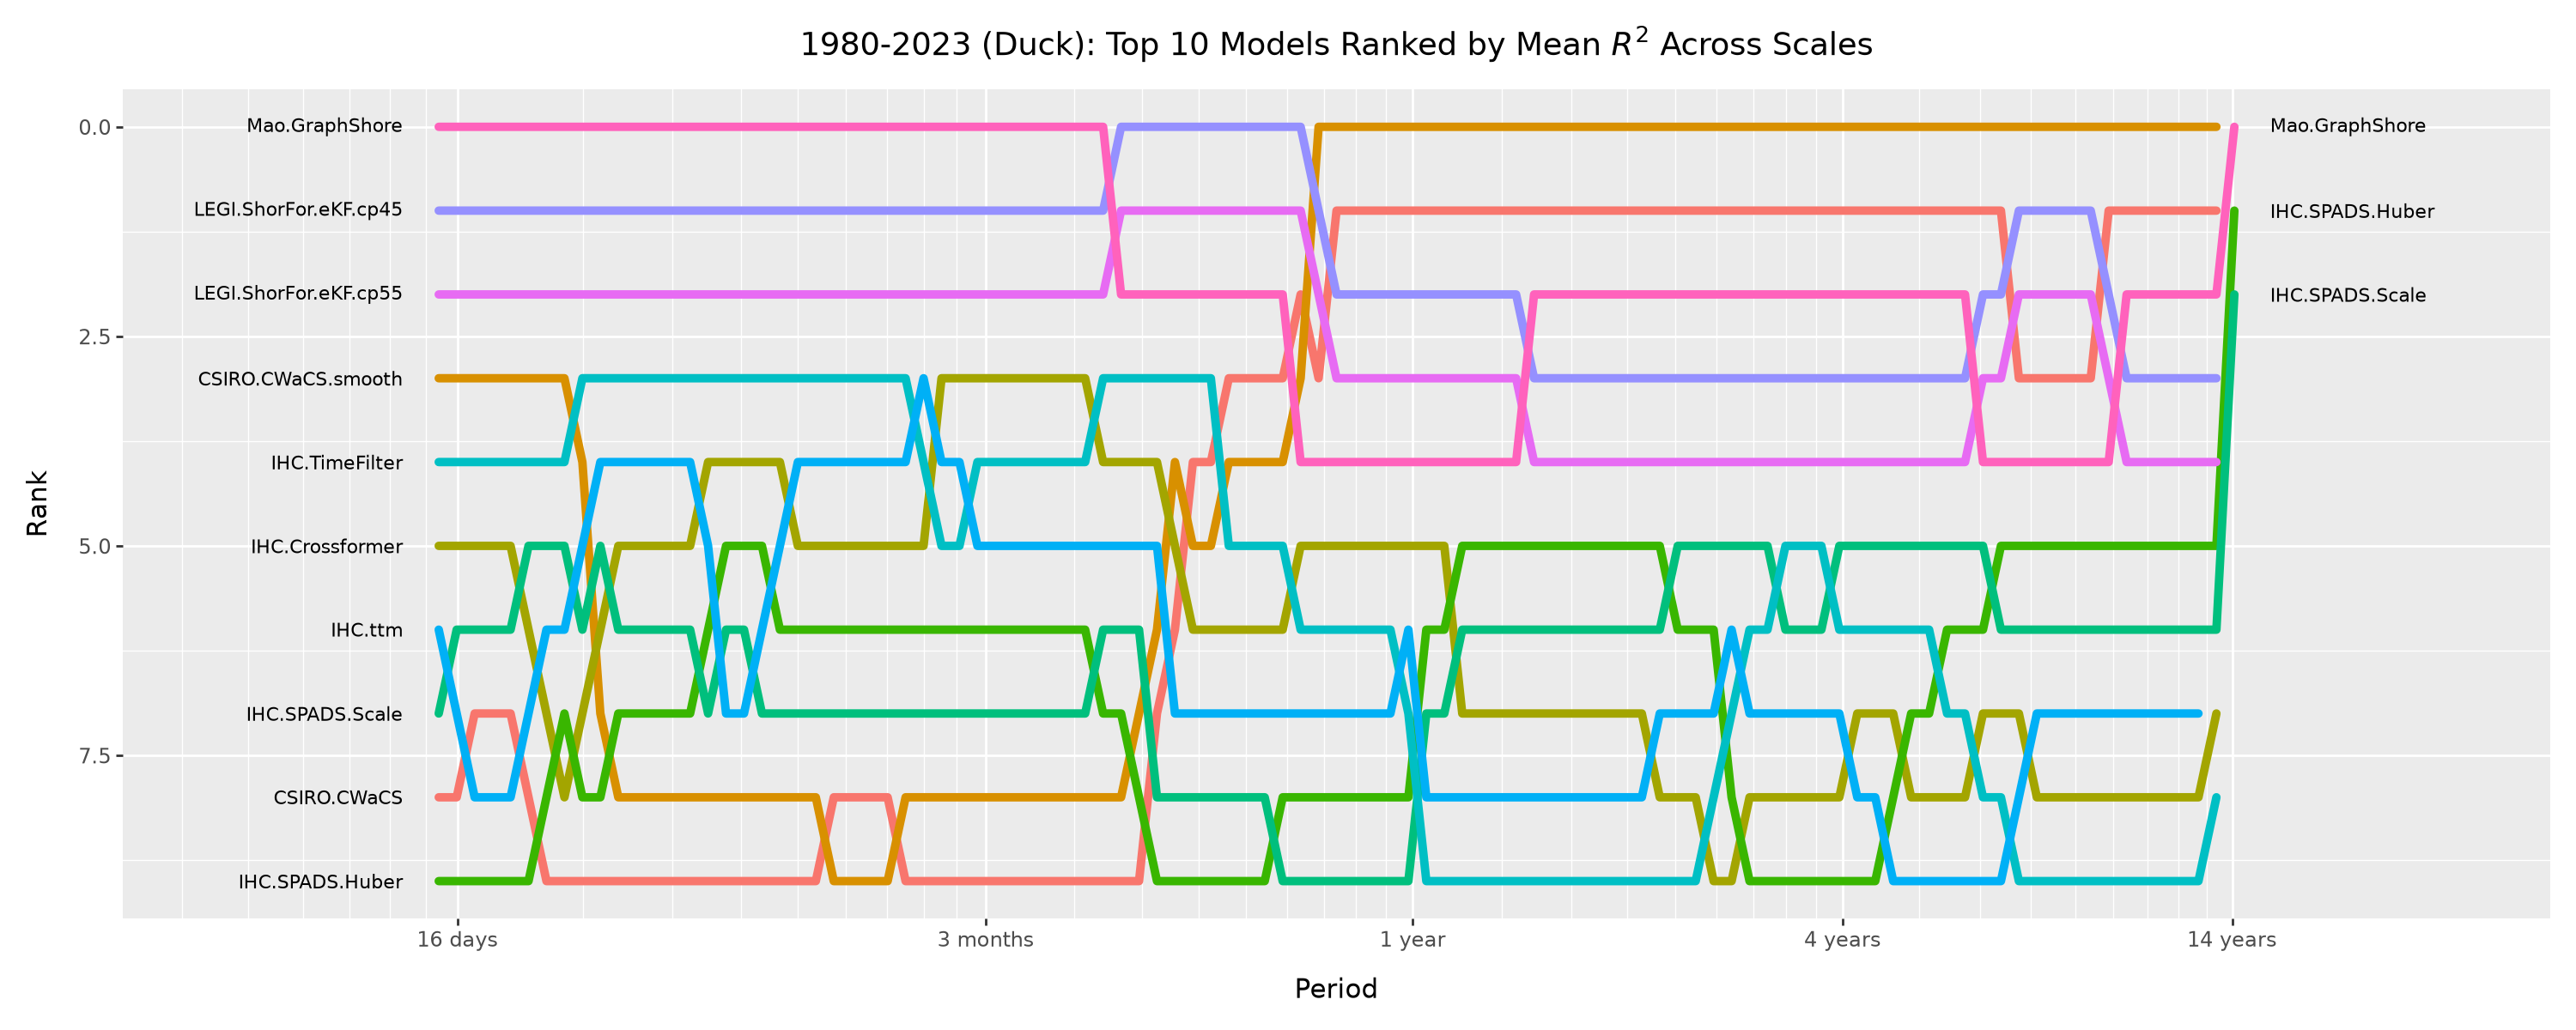

In [113]:
p = (
    pn.ggplot(df_nonan)
    + pn.geom_path(
        pn.aes('period', 'rank', group='model', color='model'),
        size=2,
        lineend='round',
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].min()],
        ha='right',
        size=8,
        nudge_x=-0.05,
    )
    + pn.geom_text(
        pn.aes('period', 'rank', label='model'),
        data=df_nonan[df_nonan['period'] == df_nonan['period'].max()],
        ha='left',
        size=8,
        nudge_x=0.05,
    )
    + pn.scale_x_log10(
        breaks=[2, 17, 31*3, 367, 366*4, 366*14],
        labels=lambda breaks: list(map(wavelet.format_period, breaks)),
        expand=(0.15, 0, 0.15, 0),
    )
    + pn.scale_y_reverse()
    #+ pn.scale_fill_hue()
    + pn.labs(x='Period', y='Rank', fill='Model', title=f'1980-2023 (Duck): Top {k} Models Ranked by Mean $R^2$ Across Scales')
    + pn.theme(figure_size=(15, 6), legend_position='none')
)
p.save('../figures/topk-ranks.png')
p